In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression ,Ridge , Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score , mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_diabetes

In [35]:
diabetes = load_diabetes()

In [36]:
diabetes

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]], shape=(442, 10)),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142.

In [37]:
x = pd.DataFrame(diabetes.data , columns=diabetes.feature_names)
y = pd.Series(diabetes.target , name='diabetes_progress')

In [38]:
x.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [39]:
y.head()

0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: diabetes_progress, dtype: float64

In [40]:
x.isnull().sum()

age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64

<Axes: >

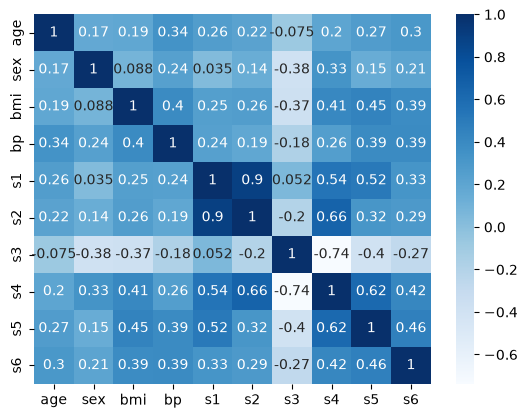

In [41]:
import seaborn as sns
sns.heatmap(x.corr() , cmap='Blues' , annot=True)

In [42]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [43]:
scaler=StandardScaler()

x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [44]:
models = {
    'Linear' : LinearRegression() , 'Ridge' : Ridge(alpha=1) ,'Lasso' :Lasso(alpha=0.1)
}

In [46]:
for name , model in models.items():
    model.fit(x_train , y_train)

    train_pred = model.predict(x_train)
    test_pred = model.predict(x_test)

    print(f'model : {name}')
    print(f'training mse : {mean_squared_error(y_train , train_pred)}')
    print(f'testing mse : {mean_squared_error(y_test , test_pred)}')
    print(f'training r2 : {r2_score(y_train , train_pred)}')
    print(f'testing r2 : {r2_score(y_test , test_pred)}')
    print()

model : Linear
training mse : 2868.5497028355776
testing mse : 2900.193628493482
training r2 : 0.5279193863361498
testing r2 : 0.4526027629719195

model : Ridge
training mse : 2870.296117291624
testing mse : 2892.0145657501735
training r2 : 0.5276319768458047
testing r2 : 0.45414652070698214

model : Lasso
training mse : 2872.7908516352636
testing mse : 2884.6242887352123
training r2 : 0.5272214154674504
testing r2 : 0.45554139902790414



In [47]:
coefs = pd.DataFrame({
    'features' : diabetes.feature_names,
    'Linear' : models['Linear'].coef_ , 'Ridge' : models['Ridge'].coef_ , 'Lasso' : models['Lasso'].coef_
})

In [48]:
coefs

,features,Linear,Ridge,Lasso
0,age,1.753758,1.807342,1.730451
1,sex,-11.511809,-11.448190,-11.316359
2,bmi,25.607121,25.732699,25.824627
3,bp,16.828872,16.734300,16.644252
4,s1,-44.448856,-34.671954,-29.358412
5,s2,24.640954,17.053075,13.275844
6,s3,7.676978,3.369914,0.547948
7,s4,13.138784,11.764260,10.236168
8,s5,35.161195,31.378384,29.632826
9,s6,2.351364,2.458139,2.393475
